In [1]:
from hexgrid import HexCoord, HexGrid, build_obstacle_map, VelocityState, get_neighbors_at_radius, hdist
from hexstarrl import ReplayBuffer, ExperienceCollector, EnvironmentStore, HUNetTDTrainer, HUNetStateEncoder, ValueNetwork_HUNet, RLState

from hexstar import HStarProblem, HStarSearch, h_cost_travel_time_euclidean, construct_full_solution, BidHStarSearch, calculate_path_smoothness, travel_time_euclidean
from hexplot import plot_hex_grid_2

import random
from tqdm.auto import tqdm


In [2]:
import torch
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)


Device: cuda


In [3]:
center = HexCoord(0,0)
start_v = VelocityState(0, None) # 0 speed, unspecified direction (allows expansion in any direction at root)
goal_v = VelocityState(0, None) # matches any direction as long as location matches. 

GOAL=HexCoord(q=-39, r=-2)


In [4]:
a_max = 3 # acceleration ability
a_min = 1 # deceleration ability
a_lat = 7 # maximum lateral g-force allowed by the agent

In [5]:
num_maps = 1
radius = 50
hex_size = 1
obs_densities = [0.15, 0.35] # Random range

In [6]:
n_step = 2

In [7]:
def random_start_goal(center, radius, min_distance_ratio=0.5):
    while True:
        q1 = random.randint(-radius + 1, radius - 1)
        r1 = random.randint(
            max(-radius + 1, -q1 - radius + 1),
            min(radius - 1, -q1 + radius - 1)
        )

        q2 = random.randint(-radius + 1, radius - 1)
        r2 = random.randint(
            max(-radius + 1, -q2 - radius + 1),
            min(radius - 1, -q2 + radius - 1)
        )

        start = HexCoord(center.q + q1, center.r + r1)
        goal = HexCoord(center.q + q2, center.r + r2)

        distance = (
            abs(start.q - goal.q)
            + abs(start.r - goal.r)
            + abs((start.q + start.r) - (goal.q + goal.r))
        ) // 2

        if distance >= radius * min_distance_ratio:
            return start, GOAL,  #goal

In [8]:
# Populate the environment store

map_configs = [
    (
        "clustered_n",
        {
            "n": 100,
            "min_cluster_size": 40,
            "max_cluster_size": 60,
            # "exclude_radius": 2,
        },
    ),
    # (
    #     "random_n",
    #     {
    #         "n": 100,
    #     },
    # ),
]


replay_buffer = ReplayBuffer(capacity = 2_000_000)
environment_store = EnvironmentStore()
experience_collector = ExperienceCollector(replay_buffer, environment_store)

from tqdm.auto import tqdm

progress = tqdm(
    range(num_maps),
    desc="Generating maps",
    unit="map",
)
for seed in progress:

    obs_density = random.uniform(*obs_densities)
    n = int(obs_density * 3 * radius * (radius + 1))
    
    map_type, map_params = random.choice(map_configs)
    #print(map_type)
    map_params['n'] = n
    start, goal = random_start_goal(
        center,
        radius,
        min_distance_ratio=0.60,
    )

    obstacles = set(
        build_obstacle_map(
            center=center,
            radius=radius,
            seed=seed,
            exclude=[start, goal],
            types=[
                (
                    map_type,
                    map_params.copy(),
                )
            ],
        ).keys()
    )

    obstacles.update(
        get_neighbors_at_radius(
            HexCoord(0, 0),
            radius,
        )
    )

    hex_grid = HexGrid(
        hex_size,
        obstacles = obstacles,
        center = center,
        radius = radius,
    )
    environment_store.add(
        seed, # environment_id
        hex_grid,
    )
    problem = HStarProblem(
        hex_grid,
        start,
        goal,
        a_max,  
        a_min,  
        start_v = start_v,
        goal_v = goal_v,
        collision_radius = 0,
        heuristic = h_cost_travel_time_euclidean,
        n_step = n_step,
        
    )
    hs = BidHStarSearch(
        problem = problem,
        bidirectional = False,
        experience_collector=experience_collector,
        environment_id = seed,
    )
    fsolution = hs.search()
    f_soln_path = construct_full_solution(fsolution)


Generating maps:   0%|          | 0/1 [00:00<?, ?map/s]

<Axes: >

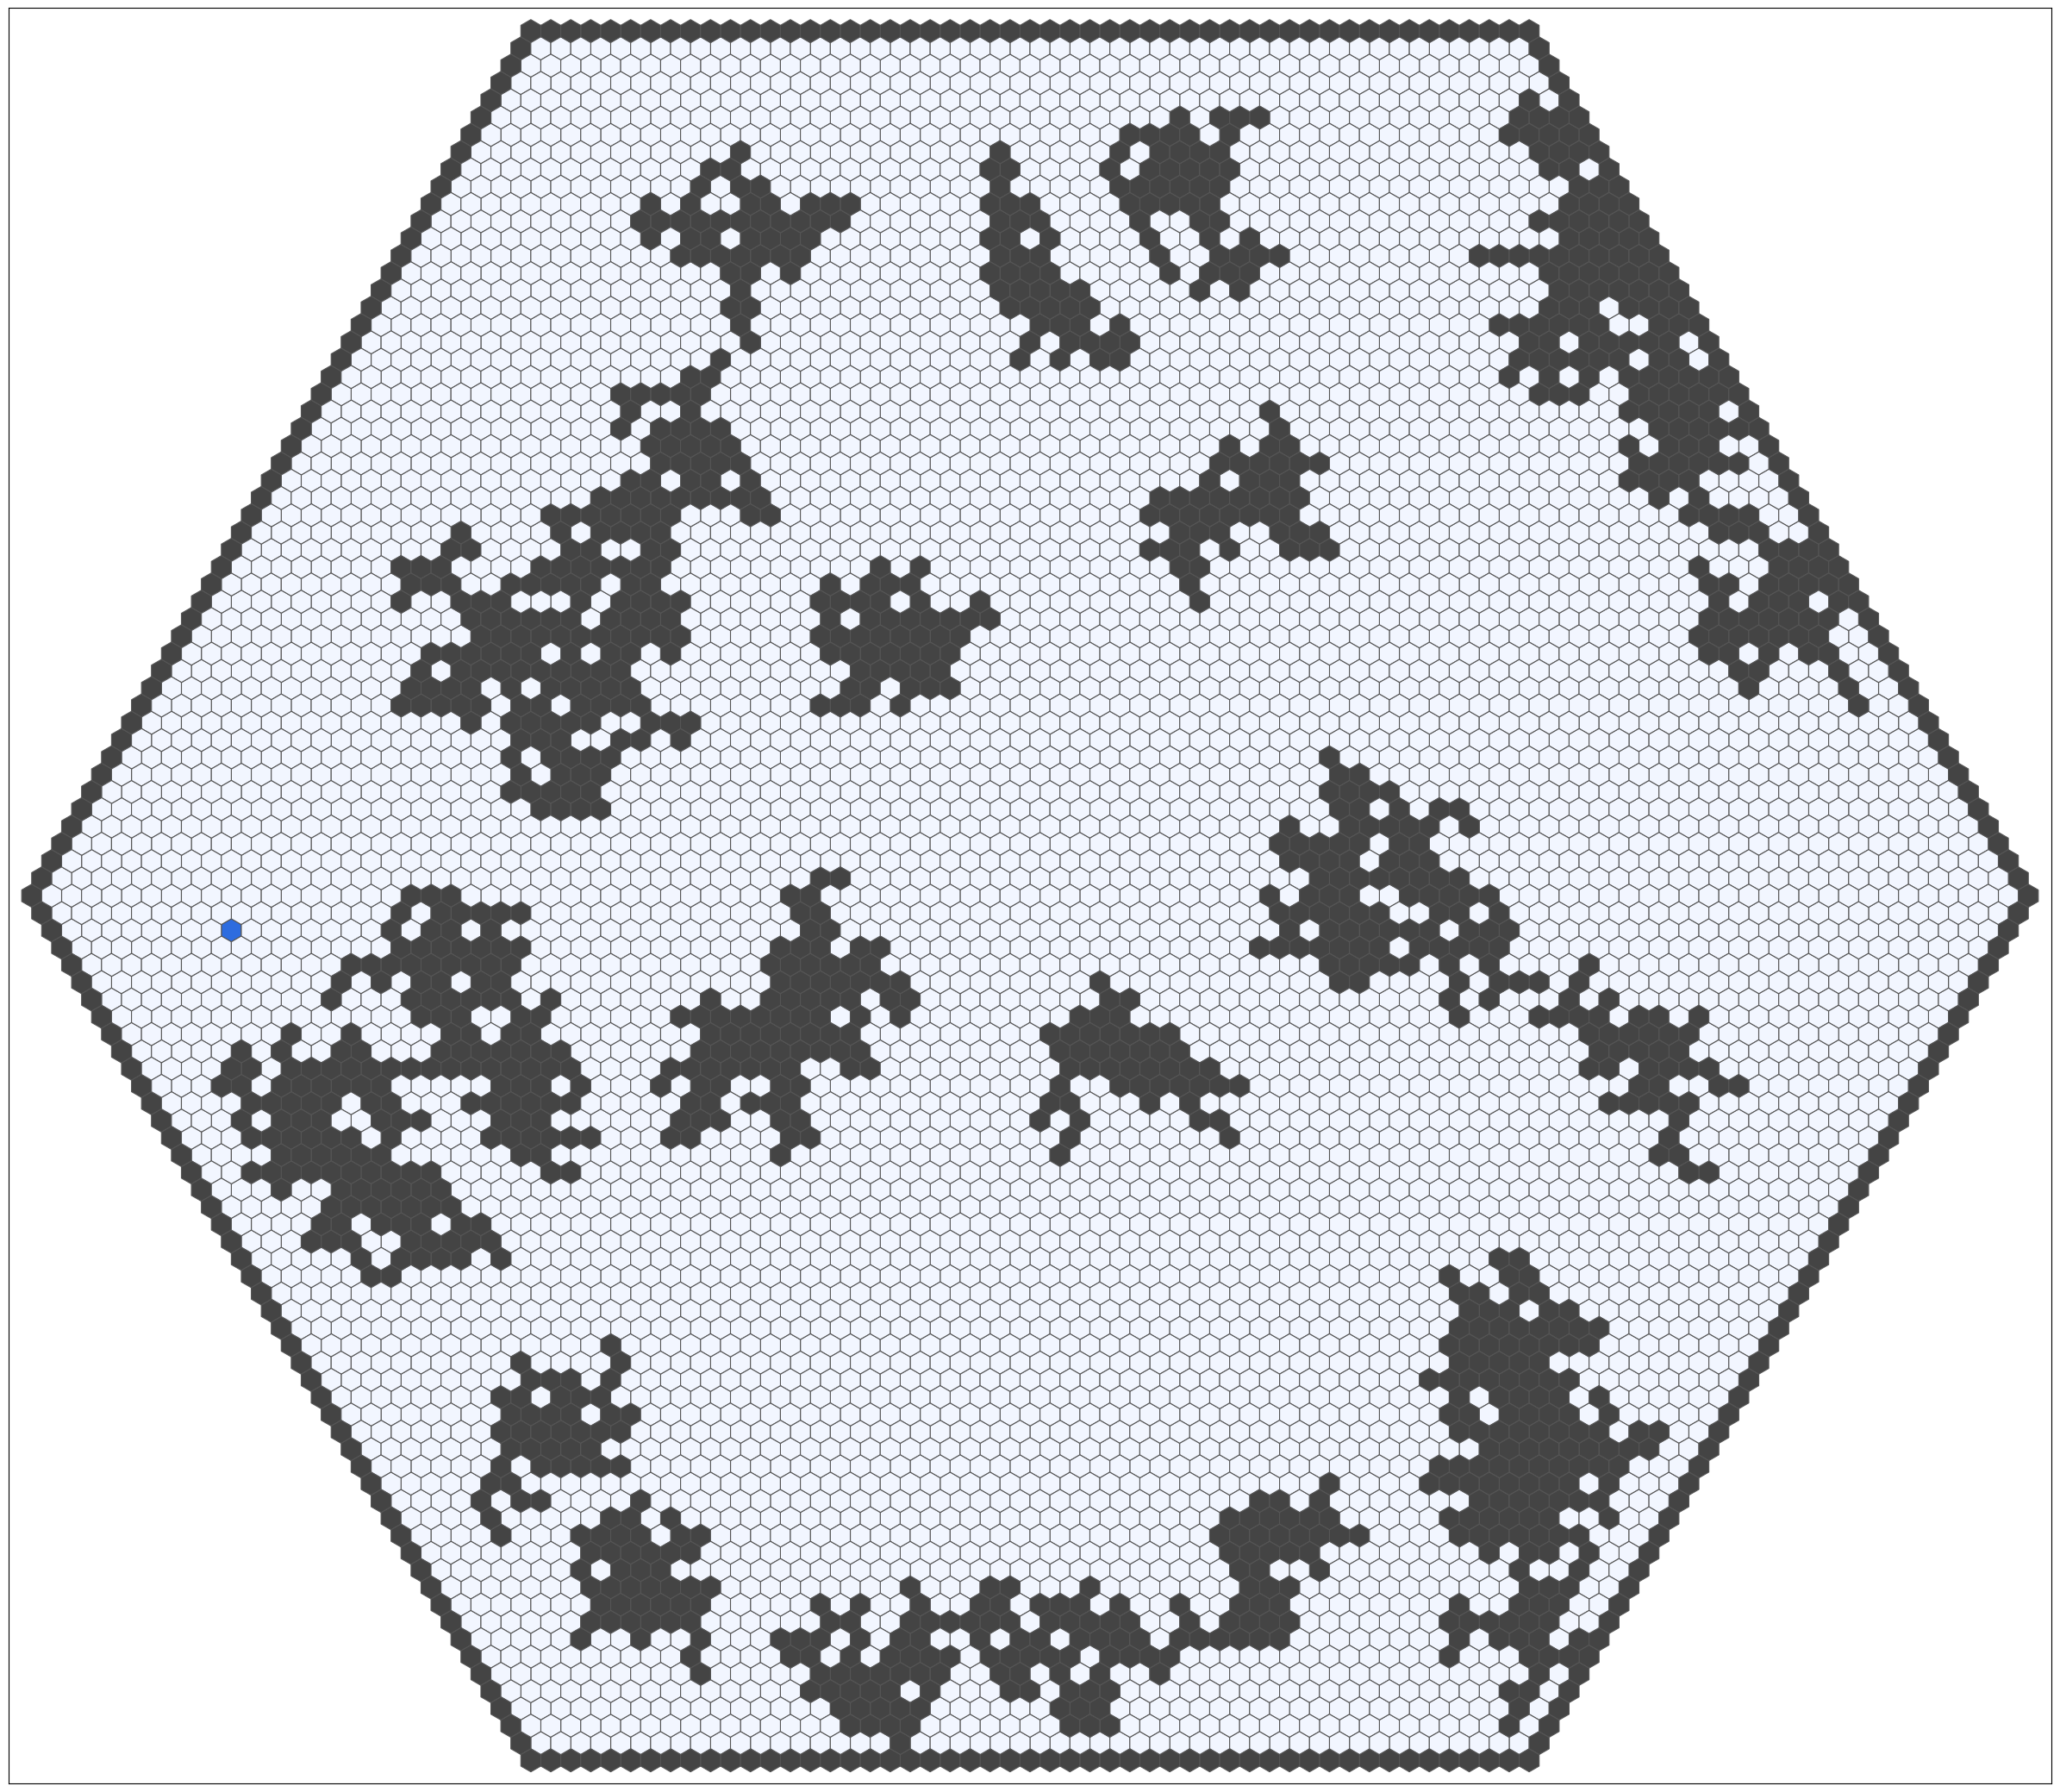

In [9]:
plot_hex_grid_2(
    obstacles=obstacles,
    start=goal,
    goal=goal,
    center=center,
    radius=radius,
    hex_size=hex_size,
    #path=predictions,
    #ax=ax,
    draw_axes=False,
    show_axis_legend=False,
    figsize=(24,24)
)

In [10]:
encoder = HUNetStateEncoder()

value_network = ValueNetwork_HUNet(
    encoder=encoder,
)

trainer = HUNetTDTrainer(
    model=value_network,
    replay_buffer=replay_buffer,
    environment_store=environment_store,
    learning_rate=1e-3,
    gamma=1.0,
    target_update_every=5,
)

In [11]:
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

def train_model(
    trainer,
    problem,
    search_callback=None,
    steps=10000,
    batch_size=64,
    search_every=100,
    print_every=100,
    plot=True,
):
    losses = []

    progress = tqdm(
        range(steps),
        desc="Training",
        unit="step",
    )

    for step in progress:

        # Periodically generate fresh experience.
        if (
            search_callback is not None
            and search_every
            and step % search_every == 0
        ):
            search_callback()

        metrics = trainer.train_step(
            problem,
            batch_size=batch_size,
        )

        losses.append(metrics)

        progress.set_postfix(
            loss=f"{metrics['loss']:.4f}",
            prediction=f"{metrics['mean_prediction']:.4f}",
            target=f"{metrics['mean_target']:.4f}",
        )

        if print_every and step % print_every == 0:
            tqdm.write(
                f"{step}: {metrics} | "
                f"buffer={len(trainer.replay_buffer)}"
            )

    if plot:
        loss_values = [
            metrics["loss"]
            for metrics in losses
        ]

        plt.plot(loss_values)
        plt.xlabel("Training Step")
        plt.ylabel("MSE Loss")
        plt.title("TD Training Loss")
        plt.show()

    return losses


In [12]:
def collect_experience():

    environment_id = random.choice(
        list(environment_store.environments.keys())
    )

    hex_grid = environment_store.get(
        environment_id
    )

    start, goal = random_start_goal(
        center,
        radius,
        min_distance_ratio=0.5,
    )

    
    problem = HStarProblem(
        hex_grid,
        start,
        goal,
        a_max,  
        a_min,  
        start_v = start_v,
        goal_v = goal_v,
        collision_radius = 0,
        heuristic = lambda a,b: 0, # h_cost_travel_time_euclidean,
        n_step = n_step,   
    )
    
    hs = BidHStarSearch(
        problem=problem,
        bidirectional=False,
        experience_collector=experience_collector,
        environment_id=environment_id,
    )

    solution_path = hs.search()

    # trainer.train_solution(
    #     solution_path,
    #     hex_grid,
    #     problem.goal,
    # )

In [13]:
# losses = train_model(
#     trainer,
#     problem,
#     search_callback=collect_experience,
#     steps=2000,
#     batch_size=16,
#     search_every=25,
#     print_every=50,
# )

Training:   0%|          | 0/1000 [00:00<?, ?step/s]

0: {'loss': 0.0941682681441307, 'mean_prediction': 0.5914918780326843, 'mean_target': 0.8615979552268982} | buffer=51899
20: {'loss': 0.08256664872169495, 'mean_prediction': 1.9014990329742432, 'mean_target': 2.157722234725952} | buffer=646132
40: {'loss': 0.1385646015405655, 'mean_prediction': 3.664391279220581, 'mean_target': 3.981632709503174} | buffer=646228
60: {'loss': 0.11849234998226166, 'mean_prediction': 6.289126396179199, 'mean_target': 6.51976203918457} | buffer=2000000
80: {'loss': 0.16877898573875427, 'mean_prediction': 7.84917688369751, 'mean_target': 8.097840309143066} | buffer=2000000
100: {'loss': 0.35510921478271484, 'mean_prediction': 8.869945526123047, 'mean_target': 9.111021041870117} | buffer=2000000
120: {'loss': 0.2363106906414032, 'mean_prediction': 10.38222885131836, 'mean_target': 10.555004119873047} | buffer=2000000
140: {'loss': 0.22597627341747284, 'mean_prediction': 11.018135070800781, 'mean_target': 11.36876392364502} | buffer=2000000
160: {'loss': 0.37

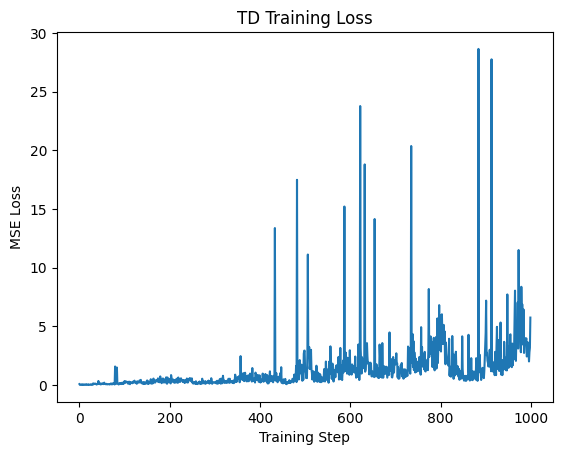

In [14]:
losses = train_model(
    trainer,
    problem,
    search_callback=collect_experience,
    steps=1000,
    batch_size=64,
    search_every=10,
    print_every=20,
)

In [15]:
for sample in replay_buffer.sample(3):

    environment = environment_store.get(
        sample.environment_id
    )
    
    prediction = value_network.predict(
        problem=problem,
        state=sample.state,
        goal=sample.goal,
        environment=environment,
    )

    euclidian_h = travel_time_euclidean(
        sample.state.location, 
        sample.goal.location, 
        sample.state.velocity.magnitude, 
        problem.a_min, 
        problem.grid.hex_size
    )
    if sample.terminal:
        target = sample.cost
    else:
        next_prediction = value_network.predict(
            problem=problem,
            state=sample.next_state,
            goal=sample.goal,
            environment=environment,
        )
    
        target = sample.cost + next_prediction
    print("------------------------------------------------")
    print("State:", sample.state)
    print("Goal:", sample.goal)
    print("Environment:", sample.environment_id)
    print("Euclidian h:", euclidian_h)
    
    print("Predicted h:", prediction)
    print("TD target:", target)
    print("Difference:", prediction - target)
print("------------------------------------------------")


------------------------------------------------
State: RLState(location=HexCoord(q=7, r=24), velocity=VelocityState(magnitude=19.570973696893702, direction=HexCoord(q=-1, r=-1)))
Goal: RLState(location=HexCoord(q=-39, r=-2), velocity=VelocityState(magnitude=0, direction=None))
Environment: 0
Euclidian h: 4.960295207639348
Predicted h: 41.89515686035156
TD target: 41.02942115744937
Difference: 0.8657357029021924
------------------------------------------------
State: RLState(location=HexCoord(q=-23, r=-24), velocity=VelocityState(magnitude=9.22913400792511, direction=HexCoord(q=-1, r=2)))
Goal: RLState(location=HexCoord(q=-39, r=-2), velocity=VelocityState(magnitude=0, direction=None))
Environment: 0
Euclidian h: 3.1568178316860767
Predicted h: 33.6058349609375
TD target: 31.09866357042141
Difference: 2.5071713905160884
------------------------------------------------
State: RLState(location=HexCoord(q=30, r=-21), velocity=VelocityState(magnitude=17.55671956128703, direction=HexCoord(q

In [16]:
import torch

def plot_value_network_directions(
    value_network,
    problem,
    environment,
    goal,
    velocity: float,
    center,
    radius: int,
    hex_size: float = 1.0,
):
    """Plot predicted h across the map for the six primary hex directions."""

    directions = (
        HexCoord( 1,  0),  # E
        HexCoord( 1, -1),  # SE
        HexCoord( 0, -1),  # SW
        HexCoord(-1,  0),  # W
        HexCoord(-1,  1),  # NW
        HexCoord( 0,  1),  # NE
    )

    direction_names = (
        "E",
        "SE",
        "SW",
        "W",
        "NW",
        "NE",
    )

    value_network.eval()

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 12),
    )

    axes = axes.flatten()

    # Run the expensive spatial network only once.
    with torch.no_grad():
        value_map = value_network.value_map(
            environment,
            goal.location,
        )

    obstacles = set(environment.obstacles)

    for ax, direction, direction_name in zip(
        axes,
        directions,
        direction_names,
    ):
        predictions = {}

        # Find the ordinal index corresponding to this primary direction.
        direction_index = problem.DIRECTIONS.index(
            direction
        )

        for q in range(-radius, radius + 1):
            for r in range(-radius, radius + 1):

                location = HexCoord(
                    center.q + q,
                    center.r + r,
                )

                if hdist(center, location) > radius:
                    continue

                if location in obstacles:
                    continue

                state = RLState(
                    location=location,
                    velocity=VelocityState(
                        magnitude=velocity,
                        direction=direction_index,
                    ),
                )

                prediction = value_network.predict(
                    problem=problem,
                    state=state,
                    goal=goal,
                    environment=environment,
                    value_map=value_map,
                )

                predictions[location] = prediction

        plot_hex_grid_2(
            obstacles=obstacles,
            start=goal.location,
            goal=goal.location,
            center=center,
            radius=radius,
            hex_size=hex_size,
            path=predictions,
            ax=ax,
            draw_axes=False,
            show_axis_legend=False,
            plt_title=(
                f"{direction_name} "
                f"{direction} | "
                f"v={velocity:.2f}"
            ),
        )

    plt.tight_layout()
    plt.show()

In [17]:
def plot_value_network_directions(
    value_network,
    problem,
    environment,
    goal,
    velocity,
    center,
    radius,
    hex_size=1.0,
):
    value_network.eval()

    directions = (
        HexCoord( 1,  0),
        HexCoord( 1, -1),
        HexCoord( 0, -1),
        HexCoord(-1,  0),
        HexCoord(-1,  1),
        HexCoord( 0,  1),
    )

    direction_names = (
        "E",
        "SE",
        "SW",
        "W",
        "NW",
        "NE",
    )

    # Spatial context depends only on:
    # environment + goal
    #
    # So run HexUNet once.
    with torch.no_grad():
        context_map = value_network.encode_environment(
            environment,
            goal,
        )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 12),
    )

    axes = axes.flatten()

    obstacles = set(environment.obstacles)

    for ax, direction, direction_name in zip(
        axes,
        directions,
        direction_names,
    ):
        values = {}

        for q in range(
            center.q - radius,
            center.q + radius + 1,
        ):
            for r in range(
                center.r - radius,
                center.r + radius + 1,
            ):
                location = HexCoord(q, r)

                dq = q - center.q
                dr = r - center.r

                hex_distance = max(
                    abs(dq),
                    abs(dr),
                    abs(dq + dr),
                )

                if hex_distance > radius:
                    continue

                if location in obstacles:
                    continue

                state = RLState(
                    location=location,
                    velocity=VelocityState(
                        magnitude=velocity,
                        direction=direction,
                    ),
                )

                with torch.no_grad():
                    value = value_network.value(
                        problem=problem,
                        state=state,
                        goal=goal,
                        environment=environment,
                        context_map=context_map,
                    )

                values[location] = value.item()

        plot_hex_grid_2(
            obstacles=obstacles,
            path=values,
            start=problem.start,
            center=center,
            radius=radius,
            hex_size=hex_size,
            ax=ax,
        )

        ax.set_title(
            f"{direction_name}: {direction}"
        )

    plt.tight_layout()
    plt.show()

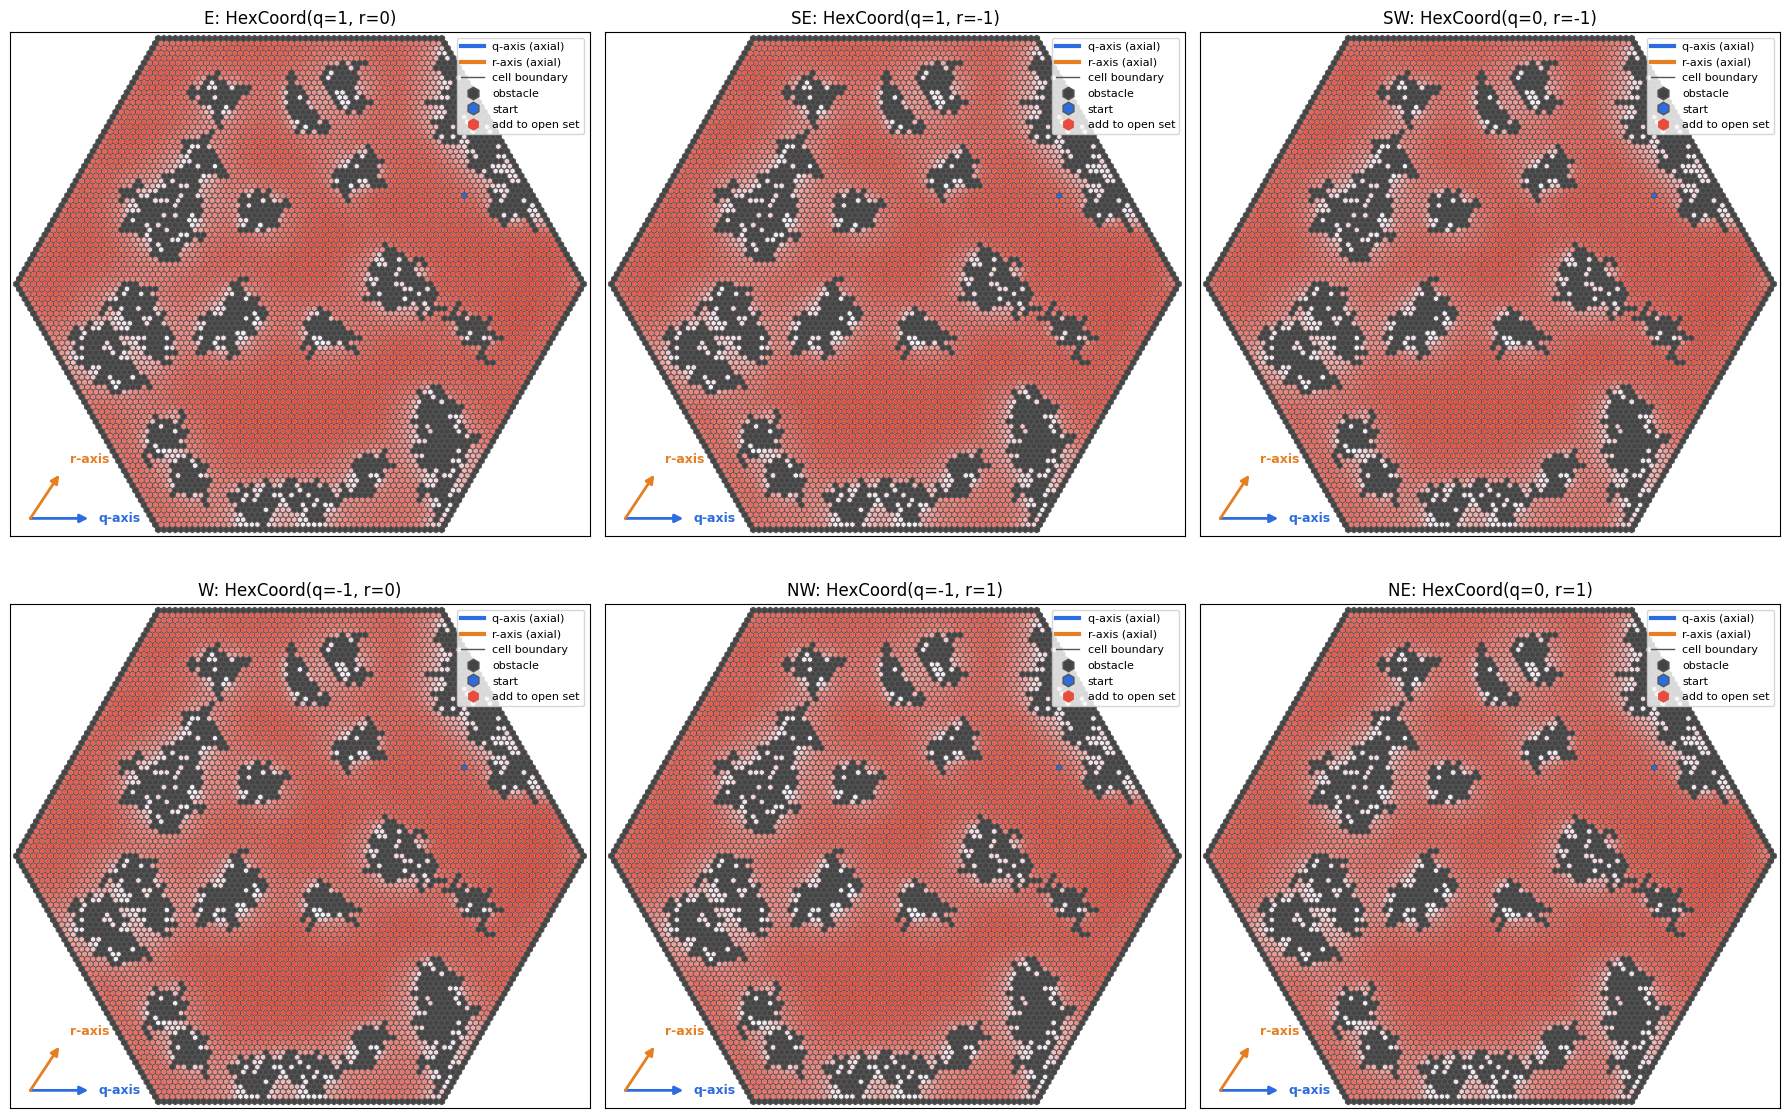

In [18]:
s = replay_buffer.sample(100)[0]

goal = RLState(
    location=problem.goal,
    velocity=problem.goal_v,
)

plot_value_network_directions(
    value_network,
    problem,
    environment_store.get(s.environment_id),
    goal,
    velocity=10,
    center=center,
    radius=radius,
    hex_size=hex_size,
)

In [19]:
def direction_sensitivity(
    value_network,
    problem,
    environment,
    goal,
    location,
    velocity,
    directions,
):
    with torch.no_grad():
        context_map = value_network.encode_environment(
            environment,
            goal,
        )

    values = []

    for direction in directions:
        state = RLState(
            location=location,
            velocity=VelocityState(
                magnitude=velocity,
                direction=direction,
            ),
        )

        value = value_network.predict(
            problem=problem,
            state=state,
            goal=goal,
            environment=environment,
            context_map=context_map,
        )

        values.append(value)

    return values

In [20]:
directions = (
    HexCoord( 1,  0),  # E
    HexCoord( 1, -1),  # SE
    HexCoord( 0, -1),  # SW
    HexCoord(-1,  0),  # W
    HexCoord(-1,  1),  # NW
    HexCoord( 0,  1),  # NE
)

values = direction_sensitivity(
    value_network,
    problem,
    environment,
    goal,
    location=HexCoord(-5, 35),
    velocity=10.5,
    directions=directions,
)

print(values)
print("direction range:", max(values) - min(values))

[34.866615295410156, 35.101112365722656, 34.95466995239258, 34.65887451171875, 34.48297119140625, 34.58622741699219]
direction range: 0.6181411743164062
